In [22]:
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict, Literal, Annotated, List
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage

from langchain_community.embeddings import HuggingFaceEmbeddings
from pinecone import Pinecone

import os

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-mpnet-base-v2")

C:\Users\ASIF\AppData\Local\Temp\ipykernel_5284\619240441.py:1: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-mpnet-base-v2")
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3553.15it/s]


In [23]:
groq_llm = ChatGroq(model="llama-3.3-70b-versatile")

In [74]:
print(groq_llm.invoke("hi").content)

It's nice to meet you. Is there something I can help you with or would you like to chat?


In [24]:
gemini_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [77]:
print(gemini_llm.invoke("hi").content)

Hi there! How can I help you today?


In [5]:
pinecone_key = os.getenv("PINECONE_API_KEY")
pc = Pinecone(api_key=pinecone_key)
index = pc.Index("mental-health-docs")

def get_relevant_info(query:str):
    text_vector = embeddings.embed_query(query)
    results = index.query(top_k=3,vector=text_vector, include_metadata=True,include_values=False)
    relevant_text =""
    for result in results['matches']:
        relevant_text +=result['metadata']['text']
    
    return relevant_text

In [84]:
relevant_text = get_relevant_info(query="Why do I feel stressed even when nothing bad is happening?")

In [6]:
web_search_tool = TavilySearchResults(max_results=3)

C:\Users\ASIF\AppData\Local\Temp\ipykernel_5284\3115963071.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  web_search_tool = TavilySearchResults(max_results=3)


In [ ]:
result = web_search_tool.invoke("what is the main cause of stress?")

In [42]:
print(result[0]['content'].replace("#",""))

The top five causes of stress, according to the American Psychological Association (APA), are:

1. Money. In an APA survey of adults, 72% reported being stressed about money. This can include retirement savings, college tuition and housing costs.
2. Job pressure. Conflicts with coworkers, bosses and work overload are some of the top sources of job stress.
3. Health. Health scares or chronic illnesses are major stressors, and they can exacerbate other stressors.
4. Relationships. Relationship issues, whether romantic or platonic, can sometimes have a negative impact on well-being.
5. Poor nutrition. Not getting adequate nutrition can be stressful for the body. Heavy caffeine consumption, for example, can cause physical symptoms of anxiety such as increased heart rate. [...] Other causes of stress include:

 Poor time management
 Becoming overwhelmed (taking on too much)
 Major life changes (death of a loved one or job loss)

More than a quarter of Americans recently surveyed by the APA 

In [28]:
class MessageType(BaseModel):
    emotional_sharing: Literal['yes', 'no'] = Field(description="does user is sharing his emotions or feelings, say 'yes' or 'no'")
    general_conversation: Literal['yes', 'no'] = Field(description="Does user message is just like general conversation with his assistan, say 'yes' or 'no'")
    mentalHealth_question: Literal['yes', 'no'] =Field(description="Does user message is simply a mental health realted question, say 'yes' or 'no'")

In [29]:
class EmotionDetection(BaseModel):
    mental_state: Literal['normal', 'Personality disorder','SuicidalThought','addiction','EatingDisorder', 'Bipolar disorder',
           'depression','Psychotic disorder','anxiety','stress','ADHD','Compulsive disorder','loneliness',
           'Post-trauma disorder'] = Field(description="analyse from user message, in which mental sate user is. detect his mental state, it may be 'normal', 'Personality disorder','SuicidalThought','addiction','EatingDisorder', 'Bipolar disorder','depression','Psychotic disorder','anxiety','stress','ADHD','Compulsive disorder','loneliness' or 'Post-trauma disorder' based on cuurent user message")

In [30]:
class Quotations(BaseModel):
    quotations: List[str] = Field(description="Return exactly 3 to 5 short quotation strings. Each item must contain only one quote and may include the author only if it is clearly known.")


In [31]:
class CheckRelevancy(BaseModel):
    context_relevancy: Literal['yes', 'no'] =Field(description="check whether given context is relevant to the user message so that LLM can relevant response, say 'yes' if context is relevant otherwise 'no'")
    relevancy_score: float =Field(description="determine relevancy score of context against given user message, give always score between 0.0 to 1.0")

In [15]:
class GraphState(TypedDict):
    user_message: str
    message_type: MessageType
    mental_state: EmotionDetection
    fine_tuned_model_response : str
    quotations: Quotations
    friendly_response: str
    relevant_info: str
    check_relevancy: CheckRelevancy
    questionare_response: str
    general_response: str

In [ ]:
llm_with_message_type = gemini_llm.with_structured_output(MessageType)


def message_type_router(state: GraphState):
    user_message = state["user_message"]

    try:
        message_type = llm_with_message_type.invoke(user_message)
        emotional_sharing = message_type.emotional_sharing
        general_conversation = message_type.general_conversation
        mentalHealth_question = message_type.mentalHealth_question

        if emotional_sharing == 'yes':
            return "emotional_meesage"
        elif general_conversation == 'yes':
            return "general_conversation"
        elif mentalHealth_question == 'yes':
            return "questional_message"
        else:
            return "irrelevant"
    except Exception:
        # Network-safe fallback routing when external LLM is unavailable.
        return "general_conversation"

In [17]:
llm_with_EmotionDetection = gemini_llm.with_structured_output(EmotionDetection)

def emotion_detection(state:GraphState):
    user_message = state['user_message']
    
    SYS_Prompt = """You are an expert in detecting mental health condition of a user based on his given message that is his emotion that he shares with you. 
    You just have to identify user's current menatl emotion state based on his message."""
    
    mental_state = llm_with_EmotionDetection.invoke(
        [
            SystemMessage(content=SYS_Prompt),
            HumanMessage(content=f"Given user message: \n{user_message}")
        ]
    )
    
    return {"mental_state":mental_state}
    

In [18]:
import requests
def Fine_Tuned_Model(state:GraphState):
    user_message = state['user_message']
    
    API_URL = "https://a-asif-mindease.hf.space/predict"

    response = requests.post(API_URL, json={
    "text": str(user_message)
    })
    response = response.json()['response']
    
    return {"fine_tuned_model_response":response}

In [44]:
llm_with_quotation_generator = groq_llm.with_structured_output(Quotations)

def quotation_generator(state:GraphState):
    user_message = state['user_message']
    mentalState = state['mental_state'].mental_state

    result = web_search_tool.invoke(f"{mentalState} mental health best quotes")
    web_results = []
    for res in result:
        web_results.append(res['content'])

    SYS_Prompt = """You are an expert in generating 3 to 5 short motivational quotations for a user based on their detected mental state.
    Return only the quotes as separate lines. Do not use bullets, numbering, JSON, markdown, or explanations.
    If possible, include the author in the same line only when you are confident it is accurate.
    Use the mental state, user message, and web results to choose the best quotes."""

    response = llm_with_quotation_generator.invoke(
        [
            SystemMessage(content=SYS_Prompt),
            HumanMessage(content=f"User's current Mental State: {mentalState}\n\nUser Message:\n{user_message}\n\nBased on mental state web results: {web_results}")
        ]
    )

    return {"quotations": response}

In [45]:
def friendly_response(state:GraphState):
    user_message = state['user_message']
    mentalState = state['mental_state'].mental_state
    quotes = state['quotations']
    quotations = quotes.quotations
    fineTuned_model_response = state['fine_tuned_model_response']
    
    SYS_Prompt = """You are an Expert mental health Psychologist Agent.You have to act as Real Mental Health Assistant. 
    Real mental health assistants should be:
    short, calm and structured.
    You will be given user message, his current predicted mental emotional state, list of quotes that are relevant to such mental state, to motivate user and best safe and supportive answer from a finetuned model.  
    YOU Always have to act as Real Mental Health Psychologist Assistant, based on that given finedtuned model response, and given quotes, You must has to give best supportive and friendly response that also includes quotes where suitable in answer, also keep in mind user's current mental state and if it is harmful then tries to mitigate it and normalize and motivate user by your supportive friendly response. 
    REMEMBER Real mental health assistants should be short, calm, structured, friendly and supportive. 
    Format of response should be as a Real mental health assistants.
    """
    
    response = groq_llm.invoke(
        [
            SystemMessage(content=SYS_Prompt),
            HumanMessage(content=f"User Message: \n{user_message}\n\nPredicted Mental State: {mentalState}\n\nList of relevant quotes: \n{quotations}\n\n Finetuned Model safe response: \n{fineTuned_model_response}")
        ]
    )
    friendly_response = response.content
    
    return{"friendly_response": friendly_response}

In [21]:
def getting_context(state:GraphState):
    user_message = state['user_message']
    
    relevant_text = get_relevant_info(query=str(user_message))
    
    return {"relevant_info": relevant_text}

In [25]:
llm_with_relevancy_check = groq_llm.with_structured_output(CheckRelevancy)

def checking_context_relevancy(state:GraphState):
    user_message = state['user_message']
    context = state['relevant_info']
    
    SYS_Propmt = """You are an expert in checking relevancy of context against user message. 
    based on given user message analyse whether given context is relevant or not. 
    If think it is relevant then set context_relevancy = 'yes' otherwise 'no'. 
    and also give relevancy score between 0 to 1 in float. and be honest and unbiased while checking relevancy. """
    
    relevancy_response = llm_with_relevancy_check.invoke(
        [
            SystemMessage(content=SYS_Propmt),
            HumanMessage(content=f"Given User message: \n{user_message}\n\nGiven Context: \n{context}")
        ]
    )
    
    return {"check_relevancy": relevancy_response}

In [46]:
def relevancy_router(state:GraphState):
    relevancy_response = state['check_relevancy']
    context_relevancy = relevancy_response.context_relevancy
    relevancy_score = relevancy_response.relevancy_score
    
    if context_relevancy == 'yes' and relevancy_score >.4:
        return "relevant"
    else:
        return "irrelevant"

In [47]:
def web_search(state:GraphState):
    user_message = state['user_message']
    
    results = web_search_tool.invoke(str(user_message))
    
    context = ""
    for result in results[:2]:
        context += result['content'] + "\n\n"
    
    return {"relevant_info": context}

In [32]:
def questionare_response(state:GraphState):
    user_message = state['user_message']
    context = state['relevant_info']
    
    SYS_Prompt = """You are an expert in givig best valid and acurate answers of questions related mantal health. 
    You will be given user question and also some context for topic about that user is inquiring. 
    You have to give a best and appropriate response of user question based on context and if needed use your valid relevant knowledge. 
    You have to give response in well-formated and structured answer so that user is satisfied with reponse.
    Answer should be cleaned, short and structured"""
    
    response = groq_llm.invoke(
        [
            SystemMessage(content=SYS_Prompt),
            HumanMessage(content=f"User Question: \n{user_message}\n\nContext: \n{context}")
        ]
    )
    
    response = response.content
    
    return {"questionare_response": response}

In [33]:
def general_response(state: GraphState):
    user_message = state['user_message']

    SYS_Prompt = """You are a Personalized Mental Health Assistant for a user.
    Based on user message give best responsive, appropriate, friendly and interactive response based on user message.
    Always give clean, short and structured response according to user message"""

    try:
        response = groq_llm.invoke(
            [
                SystemMessage(content=SYS_Prompt),
                HumanMessage(content=f"User Message: {user_message}")
            ]
        )
        general_response = response.content
    except Exception:
        general_response = (
            "I am having trouble connecting to external services right now. "
            "Please try again in a moment. If this feels urgent or you might harm yourself, "
            "contact local emergency services or a trusted person immediately."
        )

    return {"general_response": general_response}

In [48]:
builder = StateGraph(GraphState)

In [49]:
builder.add_node("emotion_detection",emotion_detection)
builder.add_node("Fine_Tuned_Model",Fine_Tuned_Model)
builder.add_node("quotation_generator",quotation_generator)
builder.add_node("friendly_response",friendly_response)
builder.add_node("getting_context",getting_context)
builder.add_node("checking_context_relevancy",checking_context_relevancy)
builder.add_node("web_search",web_search)
builder.add_node("questionare_response",questionare_response)
builder.add_node("general_response",general_response)


In [50]:
builder.add_conditional_edges(
    START,
    message_type_router,
    {
        "emotional_meesage": "emotion_detection",
        "general_conversation":"general_response",
        "questional_message":"getting_context",
        "irrelevant": END
    }
)
builder.add_edge("emotion_detection","Fine_Tuned_Model")
builder.add_edge("Fine_Tuned_Model","quotation_generator")
builder.add_edge("quotation_generator","friendly_response")
builder.add_edge("friendly_response", END)

builder.add_edge("getting_context", "checking_context_relevancy")
builder.add_conditional_edges(
    "checking_context_relevancy",
    relevancy_router,
    {
        "relevant":"questionare_response",
        "irrelevant":"web_search"
    }
)
builder.add_edge("web_search","questionare_response")
builder.add_edge("questionare_response", END)

builder.add_edge("general_response", END)

In [51]:
graph = builder.compile()

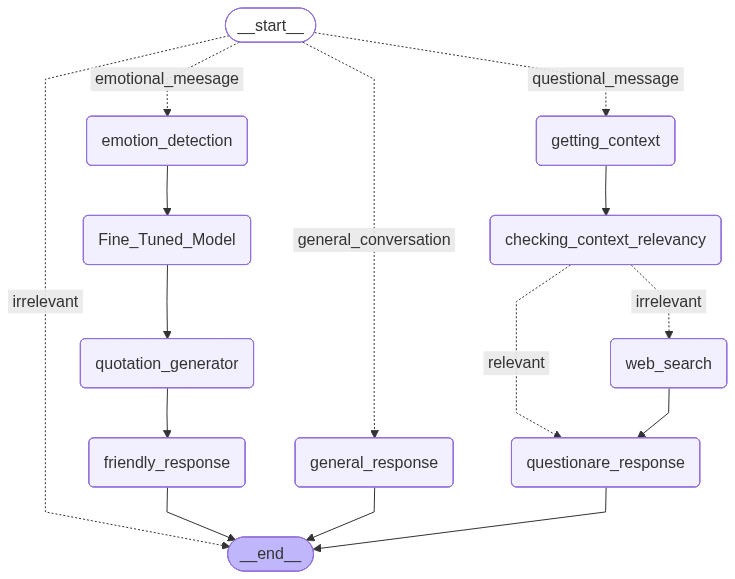

In [29]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [54]:
graph.invoke({"user_message":"Hi, what's up?"})

{'user_message': "Hi, what's up?",
 'general_response': 'Not much, just here to help. How are you feeling today?'}

In [128]:
import requests

API_URL = "https://a-asif-mindease.hf.space/predict"

response = requests.post(API_URL, json={
    "text": "I think life is too bored to live, thinking to end this useless life"
})

print(response.json()['response'])

I think life is too bored to live, thinking to end this useless life is a waste of time. I'm going to take a gun and shoot at the birds.
I am so sorry that you think this way. You should never go behind that mindset. I think it would be a good idea to talk to someone, such as a school counselor or a family member, about this. Shooting at animals is illegal and you will be arrested if you are caught. This can be a very bad thing for you. I know you feel bored, but there are plenty of other things you can do instead of hurting animals. I think you should spend some time with friends or join a club in school. You need to find something you are passionate about so you don't become bored. This way life will be more interesting and you will have something to talk about when you are older. You should try to be more open minded and try something new. Life is short, so don't take it lightly. Please talk to someone about this. They might be helpful


Real mental health assistants should be:

short
calm
structured